Project: Comparative Study of CNNs vs Lightweight Vsion Transformers when Training Data is LImiteed



In this project, the dataset is reduced by different percentages:

10%
25%
50%
100%

of the original training data in order to study the model performance in limited-data regimes.

Datset: CIFAR-10

(CIFAR-10 is a widely used benchmark dataset for image classification)

This dataset contains:

60,000 color images
image size: 32 x 32 pixels
10 object categories
6,000 images per category

The categories are:
airplane
automobile
bird
cat
deer
dog
frog
horse
ship
truck

The CIFAR-10 dataset is divided into: \\
50,000 training images \\
10,000 testing images

Models used:

1. CNN: ResNet18 -- this is our CNN baseline

2. Vision Transformer (ViT-Tiny) - tiny ViT, reduced-size version of the standard Vision Transformer architecture

3. MobileViT (Lightweight Hybrid Transformer)
MobileViT is a lightweight hybrid architecture that combines convolutional layers with transformer-based attention blocks.



Google colab:

--Enable GPU in Colab

Runtime ==> Change runtime type

Hardware accelerator ==> GPU

Save

--Restart Runtime

Runtime ==> Restart session

-- Verify GPU

In [ ]:
import torch

print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

True
Tesla T4


In [ ]:
!pip install timm -q

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import timm
import pandas as pd
import time
import random
import numpy as np

from torch.utils.data import DataLoader, Subset
from sklearn.metrics import accuracy_score, f1_score

Check the device

In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

Dataset loading with limited-data option

In [ ]:
BATCH_SIZE = 256
NUM_CLASSES = 10

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),
                         (0.2470, 0.2435, 0.2616))
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),
                         (0.2470, 0.2435, 0.2616))
])

full_train = torchvision.datasets.CIFAR10(
    root="./data", train=True, download=True, transform=train_transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data", train=False, download=True, transform=test_transform
)


100%|██████████| 170M/170M [46:44<00:00, 60.8kB/s]


In [ ]:
def make_limited_dataset(dataset, fraction=0.10, seed=SEED):
    num_samples = int(len(dataset) * fraction)
    rng = np.random.default_rng(seed)
    indices = rng.choice(len(dataset), size=num_samples, replace=False)
    return Subset(dataset, indices)

train_fraction = 0.01

train_dataset = make_limited_dataset(full_train, train_fraction, SEED)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

len(train_dataset), len(test_dataset)

(500, 10000)

Create the models

In [ ]:
def create_model(model_name, num_classes=10, pretrained=False):
    if model_name == "resnet18":
        model = torchvision.models.resnet18(weights=None)
        model.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        model.maxpool = nn.Identity()
        model.fc = nn.Linear(model.fc.in_features, num_classes)
    elif model_name == "vit_tiny":
        model = timm.create_model(
            "vit_tiny_patch16_224",
            pretrained=False,
            img_size=32,
            patch_size=4,
            num_classes=num_classes
        )
    elif model_name == "mobilevit_xxs":
        model = timm.create_model(
            "mobilevit_xxs",
            pretrained=False,
            img_size=32,
            num_classes=num_classes
        )
    else:
        raise ValueError("Unknown model name")
    return model.to(device)

In [ ]:
def create_model(model_name, num_classes=10, pretrained=False):
    if model_name == "resnet18":
        model = torchvision.models.resnet18(weights= 'IMAGENET1K_V1' if pretrained else None)
        model.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        model.maxpool = nn.Identity()
        model.fc = nn.Linear(model.fc.in_features, num_classes)
    elif model_name == "vit_tiny":
        model = timm.create_model(
            "vit_tiny_patch16_224",
            pretrained=pretrained,
            img_size=32,
            patch_size=4,
            num_classes=num_classes
        )
    elif model_name == "mobilevit_xxs":
        model = timm.create_model(
            "mobilevit_xxs",
            pretrained=pretrained,
            img_size=32,
            num_classes=num_classes
        )
    else:
        raise ValueError("Unknown model name")
    return model.to(device)

Train and evalute definitions

In [ ]:
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

    return total_loss / len(loader.dataset)

In [ ]:
def evaluate(model, loader):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = model(images)
            preds = outputs.argmax(dim=1).cpu().numpy()

            all_preds.extend(preds)
            all_labels.extend(labels.numpy())

    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average="macro")

    return acc, f1

Run a test

In [ ]:
def run_experiment(model_name, train_fraction=0.05, epochs=5, lr=1e-4, pretrained=False):
    print(f"\nRunning: {model_name}, data fraction={train_fraction}, pretrained={pretrained}")

    model = create_model(model_name, NUM_CLASSES, pretrained=pretrained)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)

    start_time = time.time()
    history = []

    for epoch in range(epochs):
        train_loss = train_one_epoch(model, train_loader, optimizer, criterion)
        test_acc, test_f1 = evaluate(model, test_loader)

        history.append({
            "model": model_name,
            "train_fraction": train_fraction,
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "test_accuracy": test_acc,
            "test_f1": test_f1
        })
        if (epoch + 1) % max(1, (epochs // 5)) == 0:
          print(
              f"Epoch {epoch+1}/{epochs} | "
              f"Loss: {train_loss:.4f} | "
              f"Acc: {test_acc:.4f} | "
              f"F1: {test_f1:.4f}"
          )

    total_time = time.time() - start_time
    params = sum(p.numel() for p in model.parameters())
    final_acc, final_f1 = evaluate(model, test_loader)

    result = {
        "model": model_name,
        "train_fraction": train_fraction,
        "epochs": epochs,
        "accuracy": final_acc,
        "macro_f1": final_f1,
        "parameters": params,
        "training_time_sec": total_time
    }

    return result, history, model

COmpare CNN, ViT and light ViT

In [ ]:
results = []
all_history = []
trained_models = {}

for model_name in ["resnet18", "vit_tiny", "mobilevit_xxs"]:
    result, history, model = run_experiment(
        model_name=model_name,
        train_fraction=train_fraction,
        epochs=20,
        lr=1e-4
    )

    results.append(result)
    all_history.extend(history)
    trained_models[model_name] = model

results_df = pd.DataFrame(results)
history_df = pd.DataFrame(all_history)

results_df


Running: resnet18, data fraction=0.01, pretrained=False
Epoch 4/20 | Loss: 2.0441 | Acc: 0.2110 | F1: 0.1499
Epoch 8/20 | Loss: 1.8332 | Acc: 0.2315 | F1: 0.1717
Epoch 12/20 | Loss: 1.6523 | Acc: 0.2458 | F1: 0.2170
Epoch 16/20 | Loss: 1.5130 | Acc: 0.2588 | F1: 0.2303
Epoch 20/20 | Loss: 1.3669 | Acc: 0.3094 | F1: 0.3011

Running: vit_tiny, data fraction=0.01, pretrained=False
Epoch 4/20 | Loss: 1.9729 | Acc: 0.2305 | F1: 0.1866
Epoch 8/20 | Loss: 1.8840 | Acc: 0.2431 | F1: 0.2176
Epoch 12/20 | Loss: 1.8447 | Acc: 0.2439 | F1: 0.2163
Epoch 16/20 | Loss: 1.7823 | Acc: 0.2479 | F1: 0.2184
Epoch 20/20 | Loss: 1.7232 | Acc: 0.2504 | F1: 0.2255

Running: mobilevit_xxs, data fraction=0.01, pretrained=False
Epoch 4/20 | Loss: 2.2999 | Acc: 0.0982 | F1: 0.0529
Epoch 8/20 | Loss: 2.2798 | Acc: 0.1091 | F1: 0.0579
Epoch 12/20 | Loss: 2.2564 | Acc: 0.1257 | F1: 0.0763
Epoch 16/20 | Loss: 2.2443 | Acc: 0.1539 | F1: 0.1064
Epoch 20/20 | Loss: 2.2184 | Acc: 0.1739 | F1: 0.1261


,model,train_fraction,epochs,accuracy,macro_f1,parameters,training_time_sec
0,resnet18,0.01,20,0.3094,0.301073,11173962,101.011103
1,vit_tiny,0.01,20,0.2504,0.225486,5362762,100.933267
2,mobilevit_xxs,0.01,20,0.1739,0.126085,954234,58.298844


In [ ]:
results_df.to_csv("cnn_vit_limited_data_results.csv", index=False)
results_df

,model,train_fraction,epochs,accuracy,macro_f1,parameters,training_time_sec
0,resnet18,0.01,20,0.3094,0.301073,11173962,101.011103
1,vit_tiny,0.01,20,0.2504,0.225486,5362762,100.933267
2,mobilevit_xxs,0.01,20,0.1739,0.126085,954234,58.298844


Plot epoch training curves

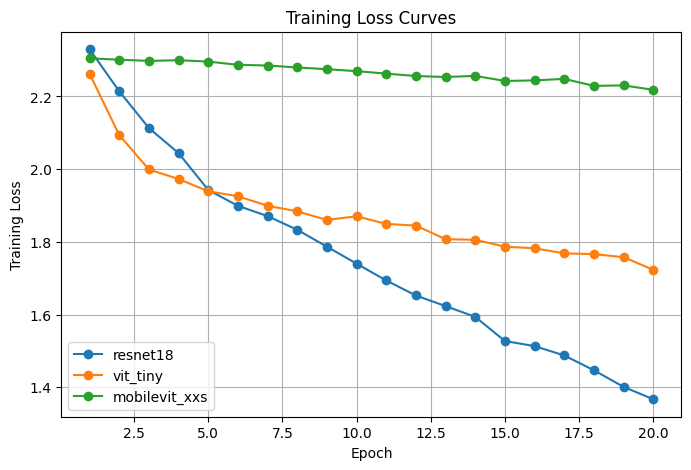

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

for model_name in history_df["model"].unique():
    subset = history_df[history_df["model"] == model_name]

    plt.plot(
        subset["epoch"],
        subset["train_loss"],
        marker="o",
        label=model_name
    )

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss Curves")
plt.legend()
plt.grid(True)
plt.show()

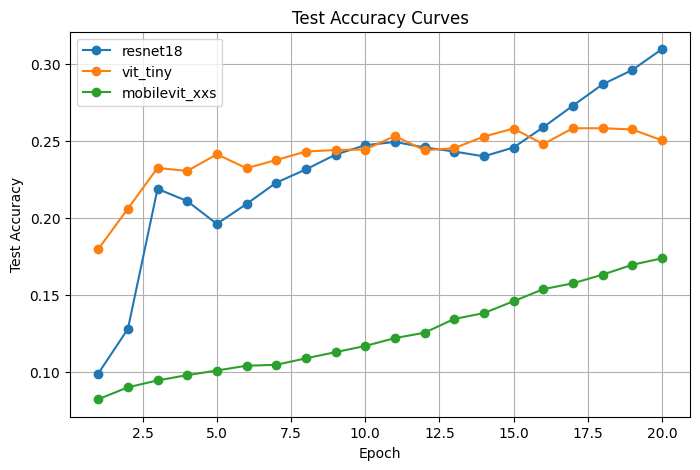

In [ ]:
plt.figure(figsize=(8,5))

for model_name in history_df["model"].unique():
    subset = history_df[history_df["model"] == model_name]

    plt.plot(
        subset["epoch"],
        subset["test_accuracy"],
        marker="o",
        label=model_name
    )

plt.xlabel("Epoch")
plt.ylabel("Test Accuracy")
plt.title("Test Accuracy Curves")
plt.legend()
plt.grid(True)
plt.show()

Confusion matrix

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

def plot_confusion_matrix(model, loader, model_name):
    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = model(images)
            preds = outputs.argmax(dim=1).cpu().numpy()

            all_preds.extend(preds)
            all_labels.extend(labels.numpy())

    cm = confusion_matrix(all_labels, all_preds)

    plt.figure(figsize=(9,9))
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )
    disp.plot(values_format="d", xticks_rotation=45)
    plt.title(f"Confusion Matrix: {model_name}")
    plt.show()

<Figure size 900x900 with 0 Axes>

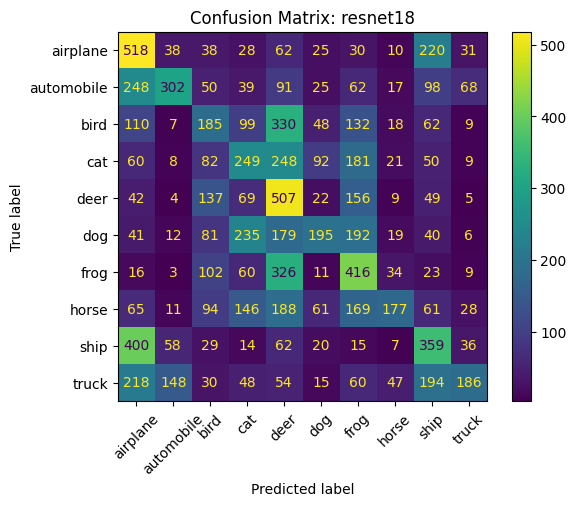

<Figure size 900x900 with 0 Axes>

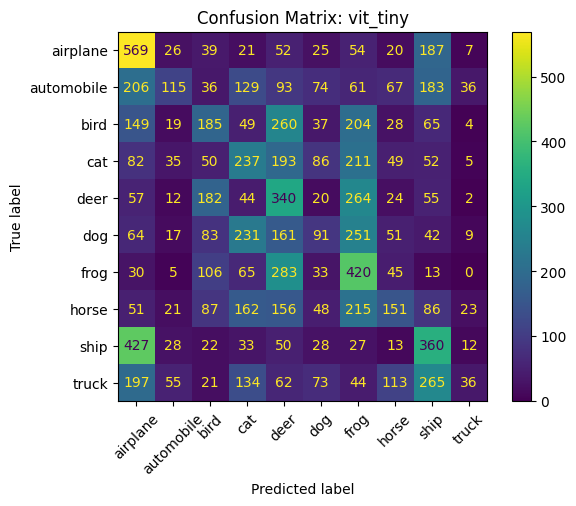

<Figure size 900x900 with 0 Axes>

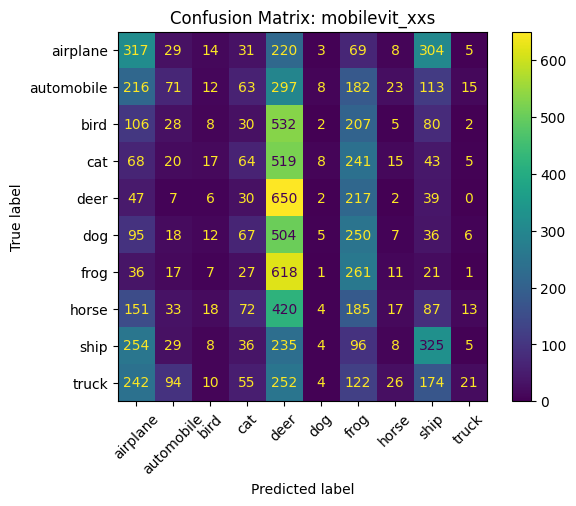

In [ ]:
for model_name, model in trained_models.items():
    plot_confusion_matrix(model, test_loader, model_name)

Results for al ldata fractions:

Compare ResNet18, ViT-Tiny, and MobileViT-XXS at 10%, 25%, 50%, and 100% CIFAR-10 training data.

In [ ]:
all_results = []
all_history = []
EPOCHS = 20

for frac in [0.01, 0.10, 0.25, 0.50, 0.75, 1.00]:
    train_dataset = make_limited_dataset(full_train, frac, SEED)
    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=2
    )

    for model_name in ["resnet18", "vit_tiny", "mobilevit_xxs"]:
        result, history, model = run_experiment(
            model_name=model_name,
            train_fraction=frac,
            epochs=EPOCHS,
            lr=1e-4
        )
        all_results.append(result)
        all_history.extend(history)

all_results_df = pd.DataFrame(all_results)
all_history_df = pd.DataFrame(all_history)
all_results_df.to_csv("full_limited_data_comparison.csv", index=False)
all_history_df.to_csv("full_training_history.csv", index=False)
display(all_results_df)


Running: resnet18, data fraction=0.01, pretrained=False
Epoch 4/20 | Loss: 2.0300 | Acc: 0.2076 | F1: 0.1590
Epoch 8/20 | Loss: 1.8345 | Acc: 0.2177 | F1: 0.1823
Epoch 12/20 | Loss: 1.6563 | Acc: 0.2953 | F1: 0.2781
Epoch 16/20 | Loss: 1.5112 | Acc: 0.3367 | F1: 0.3305
Epoch 20/20 | Loss: 1.3687 | Acc: 0.3181 | F1: 0.3022

Running: vit_tiny, data fraction=0.01, pretrained=False
Epoch 4/20 | Loss: 2.0029 | Acc: 0.2325 | F1: 0.1943
Epoch 8/20 | Loss: 1.9077 | Acc: 0.2458 | F1: 0.2217
Epoch 12/20 | Loss: 1.8478 | Acc: 0.2486 | F1: 0.2229
Epoch 16/20 | Loss: 1.8075 | Acc: 0.2376 | F1: 0.2128
Epoch 20/20 | Loss: 1.7606 | Acc: 0.2465 | F1: 0.2251

Running: mobilevit_xxs, data fraction=0.01, pretrained=False
Epoch 4/20 | Loss: 2.3028 | Acc: 0.1034 | F1: 0.0549
Epoch 8/20 | Loss: 2.2835 | Acc: 0.1023 | F1: 0.0463
Epoch 12/20 | Loss: 2.2754 | Acc: 0.1210 | F1: 0.0732
Epoch 16/20 | Loss: 2.2528 | Acc: 0.1416 | F1: 0.1044
Epoch 20/20 | Loss: 2.2486 | Acc: 0.1652 | F1: 0.1324

Running: resnet18, 

In [ ]:
EPOCHS = 20

all_results_improved = []
all_history_improved = []

for frac in [0.01, 0.10, 0.25, 0.50, 0.75, 1.00]:
    train_dataset = make_limited_dataset(full_train, frac, SEED)
    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=2
    )

    for model_name in ["resnet18", "vit_tiny", "mobilevit_xxs"]:
        result, history, model = run_experiment(
            model_name=model_name,
            train_fraction=frac,
            epochs=EPOCHS,
            lr=1e-4
        )
        all_results_improved.append(result)
        all_history_improved.extend(history)

all_results_df_improved = pd.DataFrame(all_results_improved)
all_history_df_improved = pd.DataFrame(all_history_improved)

all_results_df_improved.to_csv("full_limited_data_comparison_improved.csv", index=False)
all_history_df_improved.to_csv("full_training_history_improved.csv", index=False)

display(all_results_df_improved)

Let's visualize the results of the improved experiment and compare them with the previous results.

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for model_name in all_results_df["model"].unique():
    subset = all_results_df[
        all_results_df["model"] == model_name
    ].sort_values("train_fraction")
    plt.plot(
        subset["train_fraction"],
        subset["accuracy"],
        marker='o',
        linestyle='--',
        label=f'{model_name} (Original)',
        alpha=0.7
    )

for model_name in all_results_df_improved["model"].unique():
    subset = all_results_df_improved[
        all_results_df_improved["model"] == model_name
    ].sort_values("train_fraction")
    plt.plot(
        subset["train_fraction"],
        subset["accuracy"],
        marker='X',
        linestyle='-',
        label=f'{model_name} (Improved)',
        linewidth=2
    )

plt.xlabel("Training Data Fraction")
plt.ylabel("Test Accuracy")
plt.title("Accuracy vs Training Data Fraction (Original vs. Improved)")
plt.legend()
plt.grid(True)
plt.show()

Analyze the results

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

for model_name in all_results_df["model"].unique():

    subset = all_results_df[
        all_results_df["model"] == model_name
    ].sort_values("train_fraction")

    plt.plot(
        subset["train_fraction"],
        subset["accuracy"],
        marker='o',
        linewidth=2,
        label=model_name
    )

plt.xlabel("Training Data Fraction")
plt.ylabel("Test Accuracy")
plt.title("Accuracy vs Training Data Fraction")
plt.legend()
plt.grid(True)

plt.show()

Compare training times

In [ ]:
plt.figure(figsize=(8,5))

for model_name in all_results_df["model"].unique():

    subset = all_results_df[all_results_df["model"] == model_name]

    plt.plot(
        subset["train_fraction"],
        subset["training_time_sec"],
        marker='o',
        label=model_name
    )

plt.xlabel("Training Data Fraction")
plt.ylabel("Training Time (seconds)")
plt.title("Training Time vs Training Data Fraction")
plt.legend()
plt.grid(True)

plt.show()

Model paramter count comparison

In [ ]:
param_df = all_results_df.drop_duplicates(subset=["model"])

plt.figure(figsize=(7,5))

plt.bar(
    param_df["model"],
    param_df["parameters"]
)

plt.ylabel("Number of Parameters")
plt.title("Model Parameter Counts")

plt.show()

Important Conclusions:

ResNet18 has the largest parameter count,
yet still achieves the best accuracy,
and fastest convergence.

MobileViT has the fewest parameters,
but lower performance.

==>**CNNs Still Matter in Low-Data Regimes**

Under low-data and low-compute settings, CNNs remaineffective.

Vision Transformer models are much more data-drivenThey learn relationships through:
attention,
token interactions,
global context.

But they do NOT naturally encode:
locality,
edge structure,
translation invariance.

So they usually need:
huge datasets,
strong augmentation,
or pretraining.

The original ViT paper basically showed:

Transformers can beat CNNs,
but mainly when trained on enormous datasets.

An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale
Alexey Dosovitskiy, Lucas Beyer, Alexander Kolesnikov, Dirk Weissenborn, Xiaohua Zhai, Thomas Unterthiner, Mostafa Dehghani, Matthias Minderer, Georg Heigold, Sylvain Gelly, Jakob Uszkoreit, Neil Houlsby

https://arxiv.org/abs/2010.11929


Current setup is good for a quick comparison, but not for strong final accuracy

Accuracy limitations:

Only 20 epochs
CIFAR-10 models usually need more like 50-100 epochs from scratch.

No pretrained weights
ViTs especially perform poorly from scratch on small datasets.

Limited data fractions
At 10% data, the model only sees about 5,000 training images.

ResNet18 is not CIFAR-adapted yet
Standard ResNet18 was designed for larger ImageNet images. For 32x32 CIFAR, its first convolution and pooling are too aggressive.

To improve model performance, especially given the identified limitations, we can implement the following:

1.  **Increase Training Epochs**: The current setup uses only 20 epochs for the initial comparison and full comparison. CIFAR-10 models often require 50-100 epochs or more to converge properly, especially when training from scratch. Increasing this number will allow models more time to learn the patterns in the data.

2.  **Use Pre-trained Weights**: Vision Transformers (ViTs) and even CNNs like ResNet18 significantly benefit from pre-training on large datasets (like ImageNet). For smaller datasets like CIFAR-10, fine-tuning a model with pre-trained weights can lead to much higher accuracy and faster convergence compared to training from scratch.

Let's apply these improvements.